In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras  # type: ignore
from arch import arch_model
from src.utils import evaluate_forecasts

np.random.seed(42); tf.random.set_seed(42)

df = pd.read_csv("../data/GSPC_processed.csv", index_col=0, parse_dates=True)
r = df["log_return"]
split = int(len(r) * 0.8)
split_date = r.index[split]

# Parameters estimated on the training window only
am = arch_model(r, mean="Constant", dist="t", vol="GARCH", p=1, o=1, q=1)
res = am.fit(last_obs=r.index[split - 1], disp="off")

# Row t holds the forecast made at the end of day t for day t+1 (uses only data up to t)
gf = res.forecast(horizon=1, start=r.index[0], reindex=False).variance["h.1"]

feat = pd.DataFrame({
    "ret": r,
    "sq_ret": r ** 2,
    "abs_mean_5d": r.abs().rolling(5).mean(),
    "rv_21d": df["realized_vol_21d"],
    "garch_vol": np.sqrt(gf),
}).dropna()
print("Test starts:", split_date.date(), "| features:", list(feat.columns))

Test starts: 2023-06-06 | features: ['ret', 'sq_ret', 'abs_mean_5d', 'rv_21d', 'garch_vol']


In [2]:
train_rows = feat.index < split_date
mu, sd = feat[train_rows].mean(), feat[train_rows].std()
feat_s = (feat - mu) / sd

y_scale = (r ** 2)[r.index < split_date].mean()
target = (r ** 2).loc[feat.index] / y_scale

LOOK = 22
vals, idx, tgt = feat_s.values, feat_s.index, target.values
X, y, dates = [], [], []
for t in range(LOOK, len(idx)):
    X.append(vals[t - LOOK:t]); y.append(tgt[t]); dates.append(idx[t])
X, y, dates = np.array(X), np.array(y), pd.DatetimeIndex(dates)

train_mask = dates < split_date
X_all, y_all = X[train_mask], y[train_mask]
X_test, test_dates = X[~train_mask], dates[~train_mask]
v = int(len(X_all) * 0.9)
X_tr, y_tr, X_val, y_val = X_all[:v], y_all[:v], X_all[v:], y_all[v:]
print(X_tr.shape, X_val.shape, X_test.shape)

(3001, 22, 5) (334, 22, 5) (845, 22, 5)


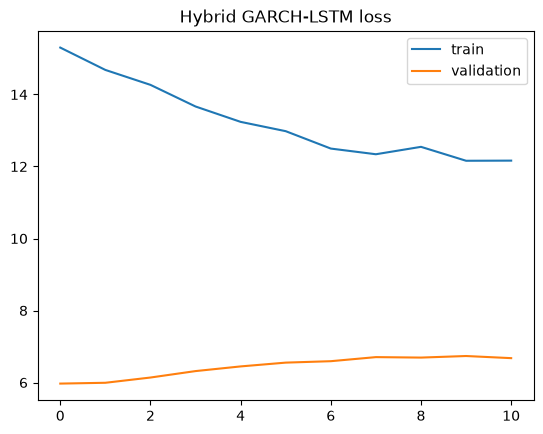

In [3]:
model = keras.Sequential([
    keras.layers.Input(shape=(LOOK, X.shape[2])),
    keras.layers.LSTM(32),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1, activation="softplus"),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
early = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
hist = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                 epochs=100, batch_size=64, callbacks=[early], verbose=0)
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="validation")
plt.legend(); plt.title("Hybrid GARCH-LSTM loss"); plt.show()

In [4]:
pred = model.predict(X_test, verbose=0).ravel() * y_scale
hybrid = pd.Series(np.clip(pred, 1e-8, None), index=test_dates, name="Hybrid GARCH-LSTM")
hybrid.to_csv("../data/hybrid_forecasts.csv")

In [5]:
garch = pd.read_csv("../data/garch_forecasts.csv", index_col=0, parse_dates=True)[["GJR-GARCH"]]
lstm = pd.read_csv("../data/lstm_forecasts.csv", index_col=0, parse_dates=True)["LSTM"]
all_fc = garch.join(lstm, how="inner").join(hybrid, how="inner").dropna()
proxy = r.loc[all_fc.index] ** 2
evaluate_forecasts(proxy, all_fc).round(4)

,RMSE,MAE,QLIKE
GJR-GARCH,3.1085,0.9430,0.5829
Hybrid GARCH-LSTM,3.3299,0.8974,0.5967
LSTM,3.3102,0.9352,0.6028


In [6]:
import statsmodels.api as sm

def dm_test(proxy, fa, fb, lags=5):
    fa, fb = fa.clip(lower=1e-8), fb.clip(lower=1e-8)
    d = ((np.log(fa) + proxy / fa) - (np.log(fb) + proxy / fb)).values
    out = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return out.tvalues[0], out.pvalues[0]

for other in ["GJR-GARCH", "LSTM"]:
    s, p = dm_test(proxy, all_fc["Hybrid GARCH-LSTM"], all_fc[other])
    print(f"Hybrid vs {other}: DM = {s:.2f}, p = {p:.3f}  (negative DM = hybrid has lower loss)")

Hybrid vs GJR-GARCH: DM = 0.35, p = 0.724  (negative DM = hybrid has lower loss)
Hybrid vs LSTM: DM = -0.55, p = 0.585  (negative DM = hybrid has lower loss)
